# МОМО: лабораторная № 1

## Численные методы линейной алгебры в задаче наименьших квадратов

# 1.1 Цель работы

Исследовать влияние ранга и обусловленности матрицы данных на численное решение задачи наи-
меньших квадратов; сопоставить прямой, итерационный и спектральный способы решения; изучить
действие сокращения размерности и регуляризации.
Работа строится как единый вычислительный эксперимент. Все сравниваемые методы используют
одно разбиение данных и согласованный способ подготовки признаков.

# 1.2 Исходные данные

## Superconductors: предсказание критической температуры

**Задача регрессии:** по числовым характеристикам химического состава материала предсказать его критическую температуру `critical_temp` в кельвинах (К). При охлаждении ниже этой температуры материал переходит в сверхпроводящее состояние. Данные содержат сведения об известных сверхпроводниках.

Одна строка — запись о материале. Файл `train.csv` содержит полный набор: **21 263 наблюдения, 81 входной признак и 1 целевой столбец**, пропуски отсутствуют по описанию UCI. В экспериментах используются **8 вещественных признаков**: средние арифметические каждого из восьми свойств элементов (`mean_...`). Эти столбцы уже рассчитаны автором; новые признаки в этом ноутбуке не создаются.

| Переменная | Роль | Тип | Смысл |
|---|---|---|---|
| `critical_temp` | Целевая переменная `y` | Вещественная | Экспериментальная критическая температура, К |
| Выбранные 8 столбцов `mean_...` | Признаки `X` | Вещественные | Средние арифметические свойств различных элементов в составе |

Целевой столбец исключается из `X` и не используется при вычислении исходных признаков: они получены из состава и свойств элементов, а температура — из экспериментальных данных.

**Источники:** [Kaggle: Superconductors](https://www.kaggle.com/datasets/anlgrbz/super-conductors), [UCI: Superconductivty Data](https://archive.ics.uci.edu/dataset/464/superconductivty+data). Автор подготовленного набора — Kam Hamidieh; исходные сведения собраны из NIMS SuperCon. Очистка и расчёт признаков описаны в [статье автора, раздел 2](https://arxiv.org/html/1803.10260).

## Восемь выбранных признаков

Для каждого свойства **химических элементов, входящих в материал**, оставляем только среднее арифметическое. Это готовые агрегаты по различным элементам состава, без учёта их долей. Например, `mean_Density` — среднее плотностей элементов, а не прямое измерение плотности самого материала.

| Используемый столбец | Свойство элемента | Единицы исходного свойства | Смысл |
|---|---|---|---|
| `mean_atomic_mass` | Атомная масса | а.е.м. | Масса атома |
| `mean_fie` | Энергия первой ионизации | кДж/моль | Энергия удаления первого электрона |
| `mean_atomic_radius` | Атомный радиус | пм | Размер атома |
| `mean_Density` | Плотность | кг/м³ | Масса на единицу объёма при стандартных условиях |
| `mean_ElectronAffinity` | Сродство к электрону | кДж/моль | Энергетическая характеристика присоединения электрона |
| `mean_FusionHeat` | Теплота плавления | кДж/моль | Энергия перехода из твёрдого состояния в жидкое |
| `mean_ThermalConductivity` | Теплопроводность | Вт/(м·К) | Способность проводить тепло |
| `mean_Valence` | Валентность | Безразмерная | Типичное число образуемых химических связей |

Единицы указаны для базовых свойств. Энтропия — безразмерная производная характеристика. При подготовке исходного набора автор добавил 1,5 к значениям сродства к электрону для корректного расчёта логарифмов. [Описание базовых свойств](https://arxiv.org/html/1803.10260#S2.SS1).


## Характеристики исходного набора и выбор признаков

Для каждого из восьми свойств уже рассчитаны следующие десять характеристик. Взвешенные версии учитывают доли элементов в химической формуле. Подробные определения, включая специальные формулы взвешенной энтропии и размаха, приведены в [разделе 2.3 статьи](https://arxiv.org/html/1803.10260#S2.SS3).

| Префикс | Характеристика | Что описывает | Пример столбца |
|---|---|---|---|
| `mean_` | Среднее арифметическое | Средний уровень свойства по различным элементам | `mean_atomic_mass` |
| `wtd_mean_` | Взвешенное среднее | Средний уровень с учётом долей элементов | `wtd_mean_atomic_mass` |
| `gmean_` | Среднее геометрическое | Мультипликативное усреднение значений | `gmean_atomic_mass` |
| `wtd_gmean_` | Взвешенное геометрическое среднее | Геометрическое усреднение с учётом долей | `wtd_gmean_atomic_mass` |
| `entropy_` | Энтропия | Равномерность нормированных значений свойства | `entropy_atomic_mass` |
| `wtd_entropy_` | Взвешенная энтропия | Равномерность с учётом долей элементов | `wtd_entropy_atomic_mass` |
| `range_` | Размах | Разность максимального и минимального значений | `range_atomic_mass` |
| `wtd_range_` | Взвешенный размах | Размах значений после умножения на доли элементов | `wtd_range_atomic_mass` |
| `std_` | Стандартное отклонение | Разброс значений вокруг среднего | `std_atomic_mass` |
| `wtd_std_` | Взвешенное стандартное отклонение | Разброс с учётом долей элементов | `wtd_std_atomic_mass` |

В исходном CSV: 8 свойств × 10 характеристик + `number_of_elements` = **81 признак**. Для этой работы из них выбираются **только 8 столбцов `mean_...`**, перечисленных выше. Другие агрегаты и `number_of_elements` в матрицу `X` не включаются. Выбор фиксирован до разбиения и не зависит от целевой переменной.


Оставим только базовые признаки среднего для упрощения

# 1.3 Постановка задачи

Для обучающей матрицы $X \in \mathbb{R}^{n \times p}$ и вектора ответов $y \in \mathbb{R}^{n}$ рассматривается задача:

$$
\min_{\beta \in \mathbb{R}^{p}} \|X\beta - y\|_2^2.
$$

Соответствующие нормальные уравнения:

$$
A\beta = b, \qquad A = X^{T}X, \qquad b = X^{T}y.
$$

Основной показатель качества прогноза — **RMSE на тестовой части**:

$$
\operatorname{RMSE}
=
\sqrt{\frac{1}{n_{\text{test}}}
\sum_{i=1}^{n_{\text{test}}}(y_i - \hat{y}_i)^2}.
$$

# 1.4 Обязательная часть

## Установка зависимостей, загрузка датасета и деление данных

Запускайте ячейки сверху вниз в Jupyter, VS Code, Google Colab или Kaggle. Требуется **Python 3.10+** и доступ в интернет. Команда `%pip` устанавливает библиотеки в окружение текущего ядра.

In [ ]:
%pip install -q "kagglehub>=1.0.3" pandas numpy "scikit-learn>=1.2" matplotlib


In [2]:
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
from IPython.display import display

DATASET_HANDLE = "anlgrbz/super-conductors/versions/1"
CSV_NAME = "train.csv"

csv_path = Path(kagglehub.dataset_download(DATASET_HANDLE, path=CSV_NAME))
print(f"CSV загружен: {csv_path}")


/Users/aleksandr/Documents/GitReps/MOMO_labs/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSV загружен: /Users/aleksandr/.cache/kagglehub/datasets/anlgrbz/super-conductors/versions/1/train.csv


In [3]:
df = pd.read_csv(csv_path)

print(f"Наблюдений: {df.shape[0]:,}")
print(f"Столбцов: {df.shape[1]}")
display(df.head())


Наблюдений: 21,263
Столбцов: 82


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


In [4]:
TARGET = "critical_temp"

assert TARGET in df.columns, f"В CSV отсутствует целевой столбец {TARGET!r}."
assert df.shape == (21263, 82), f"Неожиданный размер таблицы: {df.shape}"
assert df.select_dtypes(include="number").shape[1] == df.shape[1], "Есть нечисловые столбцы."
assert not df.isna().any().any(), "В данных обнаружены пропуски."

print(f"Признаков в исходном CSV: {df.shape[1] - 1}")
print(f"Пропусков: {int(df.isna().sum().sum())}")
print(f"Целевая переменная: {TARGET}")


Признаков в исходном CSV: 81
Пропусков: 0
Целевая переменная: critical_temp


In [5]:
SEED = 42
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

FEATURES = [
    "mean_atomic_mass",
    "mean_fie",
    "mean_atomic_radius",
    "mean_Density",
    "mean_ElectronAffinity",
    "mean_FusionHeat",
    "mean_ThermalConductivity",
    "mean_Valence",
]

X = df[FEATURES].copy()
y = df[TARGET]

rng = np.random.default_rng(SEED)
shuffled_indices = rng.permutation(df.index.to_numpy())
n_train = int(len(df) * TRAIN_FRACTION)
n_val = int(len(df) * VAL_FRACTION)

train_indices = shuffled_indices[:n_train]
val_indices = shuffled_indices[n_train:n_train + n_val]
test_indices = shuffled_indices[n_train + n_val:]

X_train, X_val, X_test = (X.loc[idx].copy() for idx in (train_indices, val_indices, test_indices))
y_train, y_val, y_test = (y.loc[idx].copy() for idx in (train_indices, val_indices, test_indices))


In [6]:
assert df.index.is_unique, "Для разбиения нужны уникальные индексы строк."
assert np.isclose(TRAIN_FRACTION + VAL_FRACTION + TEST_FRACTION, 1.0)
assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty
assert set(X_train.index) | set(X_val.index) | set(X_test.index) == set(df.index)

for features, target in ((X_train, y_train), (X_val, y_val), (X_test, y_test)):
    assert features.index.equals(target.index), "Индексы признаков и цели не совпадают."
    assert TARGET not in features.columns, "Целевой столбец попал в признаки."

split_summary = pd.DataFrame({
    "Подвыборка": ["train", "val", "test"],
    "Наблюдений": [len(X_train), len(X_val), len(X_test)],
    "Признаков": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
})
split_summary["Доля, %"] = (split_summary["Наблюдений"] / len(df) * 100).round(2)

print(f"Seed: {SEED}")
display(split_summary)


,Подвыборка,Наблюдений,Признаков,"Доля, %"
0,train,14884,8,70.0
1,val,3189,8,15.0
2,test,3190,8,15.0


Seed: 42


Определим матрицы A и b для трейновой части

In [7]:
A_train = X_train.T @ X_train
b_train = X_train.T @ y_train

## 1.4.1 Исследование матрицы данных

Для исходной и стандартизованной матриц используем SVD и одно правило численного ранга:

$$
\tau = \sigma_{\max}\max(n,p)\varepsilon_{\mathrm{mach}},
\qquad r_{\mathrm{num}} = \#\{i:\sigma_i>\tau\}.
$$

Фактический допуск вычисляется отдельно для каждой матрицы. Число обусловленности в норме 2 определяется отношением максимального сингулярного числа к минимальному. Для $X^TX$ оно вычисляется непосредственно по сформированной матрице. При полном столбцовом ранге в точной арифметике $\kappa_2(X^TX)=\kappa_2(X)^2$; в вычислениях возможны расхождения из-за округлений.


In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)

In [10]:
eigenvalues = np.linalg.eigvalsh(A_train)

singular_values = np.linalg.svd(X_train, compute_uv=False)
singular_values_std = np.linalg.svd(X_train_std, compute_uv=False)

tol = singular_values[0] * max(X_train.shape) * np.finfo(singular_values.dtype).eps
tol_std = singular_values_std[0] * max(X_train_std.shape) * np.finfo(singular_values_std.dtype).eps

rank = np.count_nonzero(singular_values > tol)
rank_std = np.count_nonzero(singular_values_std > tol_std)

A_train_std = X_train_std.T @ X_train_std

cond_X_train = singular_values[0] / singular_values[-1] if singular_values[-1] > 0 else np.inf
cond_X_train_std = singular_values_std[0] / singular_values_std[-1] if singular_values_std[-1] > 0 else np.inf
cond_A_train = np.linalg.cond(A_train, p=2)
cond_A_train_std = np.linalg.cond(A_train_std, p=2)

matrix_diagnostics = pd.DataFrame({
    "Матрица": ["До стандартизации", "После стандартизации"],
    "Наблюдений": [X_train.shape[0], X_train_std.shape[0]],
    "Признаков": [X_train.shape[1], X_train_std.shape[1]],
    "Допуск": [tol, tol_std],
    "Численный ранг": [rank, rank_std],
    "κ₂(X)": [cond_X_train, cond_X_train_std],
    "κ₂(XᵀX)": [cond_A_train, cond_A_train_std],
})

with pd.option_context("display.float_format", "{:.6e}".format):
    display(matrix_diagnostics)


,Матрица,Наблюдений,Признаков,Допуск,Численный ранг,κ₂(X),κ₂(XᵀX)
0,До стандартизации,14884,8,2.735261e-06,8,1.250998e+04,1.564997e+08
1,После стандартизации,14884,8,6.677926e-10,8,6.654204e+00,4.427844e+01


### Сингулярные числа


In [11]:
singular_values_table = pd.DataFrame({
    "Номер": np.arange(1, len(singular_values) + 1),
    "До стандартизации": singular_values,
    "После стандартизации": singular_values_std,
})

with pd.option_context("display.max_rows", None):
    display(singular_values_table)


,Номер,До стандартизации,После стандартизации
0,1,827635.041276,202.060640
1,2,43604.774072,176.373633
2,3,5096.287955,129.671406
3,4,3843.193378,121.163314
4,5,2834.127196,83.259186
5,6,1964.601062,67.083801
6,7,1054.731490,57.325417
7,8,66.157959,30.365860


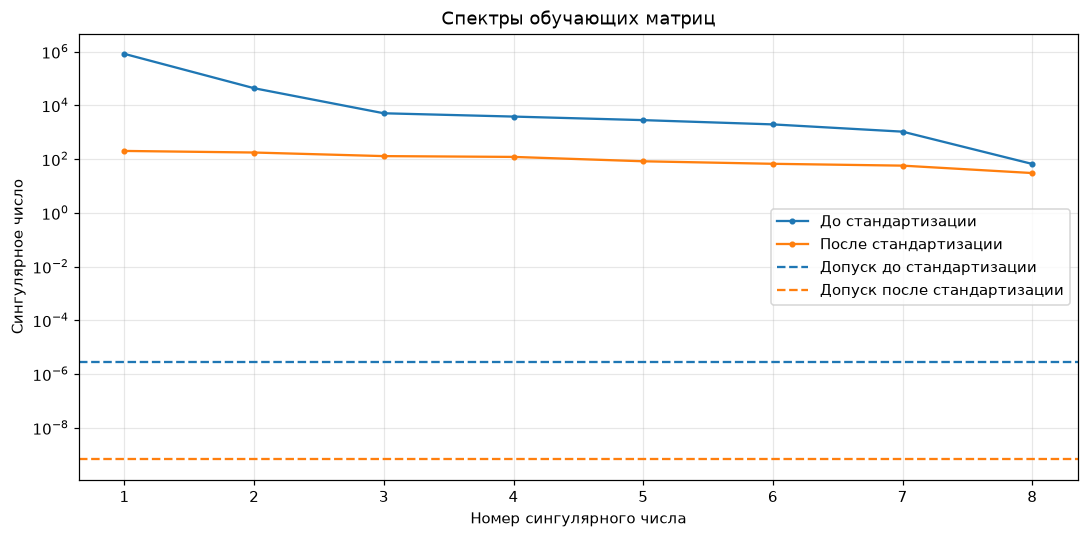

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogy(singular_values_table["Номер"], singular_values, "o-", markersize=3, label="До стандартизации")
ax.semilogy(singular_values_table["Номер"], singular_values_std, "o-", markersize=3, label="После стандартизации")
ax.axhline(tol, color="tab:blue", linestyle="--", label="Допуск до стандартизации")
ax.axhline(tol_std, color="tab:orange", linestyle="--", label="Допуск после стандартизации")
ax.set(xlabel="Номер сингулярного числа", ylabel="Сингулярное число", title="Спектры обучающих матриц")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


### Корреляционные матрицы количественных признаков

Корреляции Пирсона рассчитываются по обучающей части для 8 выбранных признаков. Положительное масштабирование и центрирование сохраняют корреляции, поэтому матрицы до и после StandardScaler должны совпадать с точностью до округления.


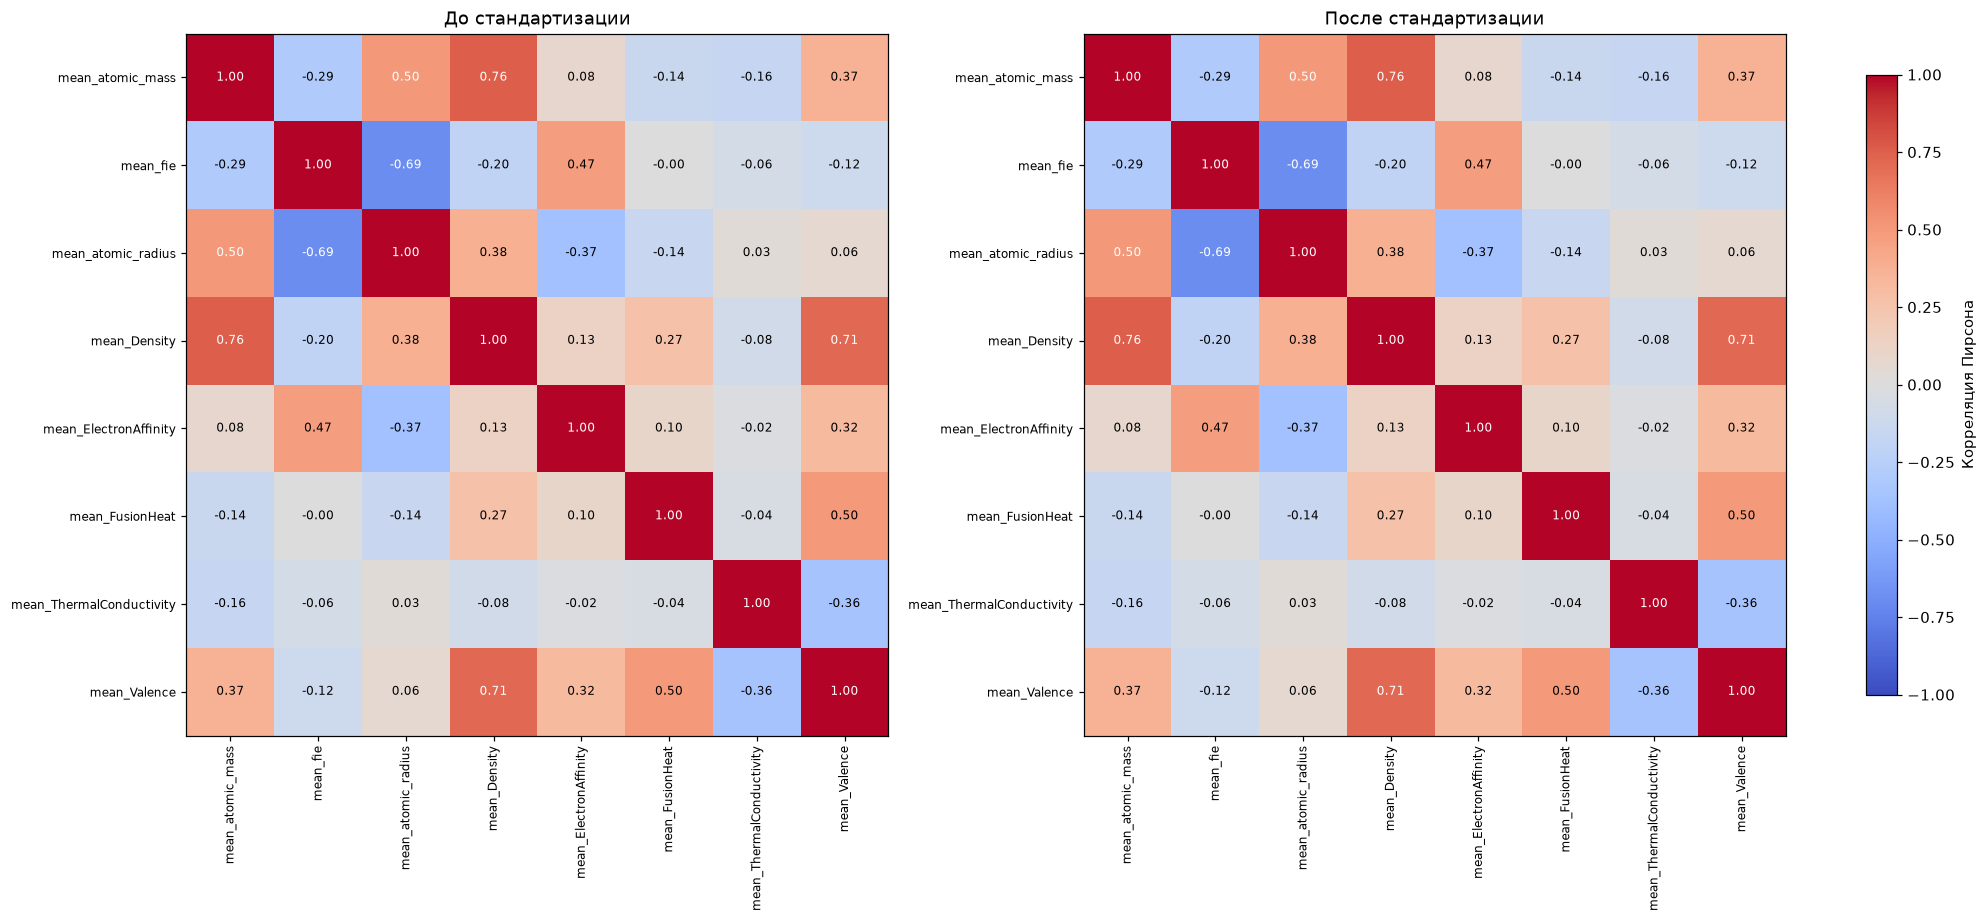

Максимальное различие корреляций: 7.549516567451064e-15


In [13]:
X_train_std_df = pd.DataFrame(X_train_std, index=X_train.index, columns=X_train.columns)

corr_train = X_train.corr(method="pearson")
corr_train_std = X_train_std_df.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 9), layout="constrained")
for ax, corr, title in zip(
    axes,
    (corr_train, corr_train_std),
    ("До стандартизации", "После стандартизации"),
):
    image = ax.imshow(corr.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
    ticks = np.arange(len(corr.columns))
    ax.set_xticks(ticks, labels=corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(ticks, labels=corr.index, fontsize=8)
    ax.set_title(title)
    for row in range(len(corr)):
        for col in range(len(corr.columns)):
            value = corr.iloc[row, col]
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(value) > 0.5 else "black")

fig.colorbar(image, ax=axes, shrink=0.7, label="Корреляция Пирсона")
plt.show()

print("Максимальное различие корреляций:", np.max(np.abs(corr_train.to_numpy() - corr_train_std.to_numpy())))


## 1.4.2. Прямое решение нормальных уравнений


## 1.4.3. Итерационное решение

## 1.4.4. Решение на основе SVD